<div style="background:rgba(128,128,128,0.05);border:1px solid rgba(128,128,128,0.26);color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));border-radius:12px;padding:28px 30px;"><div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#C2772A;">Qiskit Fall Fest Connecticut 2026 &nbsp;·&nbsp; qBraid challenge &nbsp;·&nbsp; Resource 3 of 3</span></div><div style="margin:0 0 14px 0;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:12px;letter-spacing:1px;color:rgba(128,128,128,0.98);white-space:nowrap;"><svg width="12" height="12" viewBox="0 0 24 24" fill="none" stroke="rgba(128,128,128,0.98)" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>about 40 minutes end to end</span></div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:36px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">Build <span style="color:#C2772A;">QAOA</span> for a graph problem and run it with qBraid</div><p style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:16px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;">Picture a room of six people who argue in pairs. You want to split them into two teams so that as many arguing pairs as possible end up on opposite teams. That puzzle is called <b>MaxCut</b>. It is small enough to check by hand, and it is hard in general, so it is the standard first problem for quantum optimization.</p><p style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:16px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;">In this notebook you solve MaxCut with the <b>Quantum Approximate Optimization Algorithm</b> (QAOA), then send the circuit to a qBraid device. The path:</p><ol style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:15px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;padding-left:22px;"><li style="margin:0 0 9px 0;"><b style="font-weight:600;">What MaxCut asks.</b> <span style="color:rgba(128,128,128,0.98);">The graph, and its best answer found by checking every split.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">MaxCut as a cost Hamiltonian.</b> <span style="color:rgba(128,128,128,0.98);">The same scores written as a quantum operator.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">The QAOA circuit.</b> <span style="color:rgba(128,128,128,0.98);">Three layers of gates that you build by hand.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Choosing the angles.</b> <span style="color:rgba(128,128,128,0.98);">A grid scan and a classical optimizer tune the circuit.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Reading the answer.</b> <span style="color:rgba(128,128,128,0.98);">Samples, decoded back into teams, scored against random guessing.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Submitting with qBraid.</b> <span style="color:rgba(128,128,128,0.98);">The tuned circuit runs on AWS SV1 through the qBraid SDK.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">From MaxCut to your challenge.</b> <span style="color:rgba(128,128,128,0.98);">What carries over to the Instant Insanity puzzle.</span></li></ol><p style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:16px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;">The challenge notebook uses the same recipe on a harder problem. Everything here is a building block you will reuse there.</p></div>

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#C2772A;">Before you start</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#C2772A;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#C2772A" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

Run the two cells below to install what is missing and set up plotting; the notebook defines its other helpers where it first uses them.

In [1]:
import importlib.util
import subprocess
import sys

# install only what is missing; upgrading an already-imported package can break it
NEEDED = {"qiskit": "qiskit>=1.3,<3", "qiskit_aer": "qiskit-aer>=0.15",
          "qbraid": "qbraid[qiskit]>=0.12", "matplotlib": "matplotlib",
          "networkx": "networkx", "scipy": "scipy", "pylatexenc": "pylatexenc"}
missing = [spec for mod, spec in NEEDED.items()
           if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing],
                   check=True)
print("installed:", ", ".join(missing) or "nothing, everything was already here")

installed: nothing, everything was already here


In [2]:
import io

import itertools

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

SEED = 7
GREY, VIOLET, TEAL, AMBER = "#8A8A8A", "#8B5CF6", "#0E9488", "#C2772A"
plt.rcParams.update({"figure.facecolor": "none", "axes.facecolor": "none",
                     "savefig.facecolor": "none", "savefig.edgecolor": "none",
                     "figure.dpi": 110, "axes.edgecolor": GREY,
                     "text.color": GREY, "axes.labelcolor": GREY,
                     "xtick.color": GREY, "ytick.color": GREY})


def show(fig):
    """Show a figure with a transparent background, whatever the page theme."""
    # sending the PNG ourselves stops the notebook painting a dark box behind it
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", transparent=True, bbox_inches="tight", dpi=110)
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#C2772A;">Section 1 · The problem</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#C2772A;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#C2772A" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">What does <span style="color:#C2772A;">MaxCut</span> ask for?</div>

A <b>graph</b> is a set of points, called <b>nodes</b>, joined by lines, called <b>edges</b>. Split the nodes into two groups. An edge is <b>cut</b> when its two ends land in different groups. MaxCut asks for the split that cuts the most edges.

Our graph has six nodes and eight edges. It is two triangles, joined by two edges in the middle. The next cell draws it.

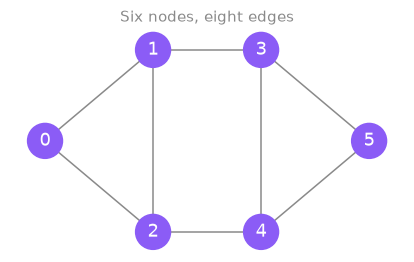

In [3]:
import networkx as nx

N = 6
EDGES = [(0, 1), (0, 2), (1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 5)]
POS = {0: (0, 1), 1: (1, 1.6), 2: (1, 0.4), 3: (2, 1.6), 4: (2, 0.4), 5: (3, 1)}
graph = nx.Graph(EDGES)


def draw_graph(colors=None, title=""):
    """Draw the graph; `colors` gives one colour per node."""
    fig, ax = plt.subplots(figsize=(4.6, 2.6))
    nx.draw_networkx(graph, POS, ax=ax, node_color=colors or [VIOLET] * N,
                     edge_color=GREY, font_color="#FFFFFF", node_size=520)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
    show(fig)


draw_graph(title="Six nodes, eight edges")

A split is a list of six bits, one per node. A 0 puts the node in one group and a 1 puts it in the other. That gives $2^6 = 64$ splits, few enough to check every one. Brute force first, always: it gives the exact answer that the quantum run must match.

In [4]:
def cut_size(bits):
    """Number of edges whose two ends sit in different groups."""
    return sum(bits[i] != bits[j] for i, j in EDGES)


splits = list(itertools.product([0, 1], repeat=N))
cuts = [cut_size(bits) for bits in splits]
best_cut = max(cuts)
best_splits = [bits for bits, cut in zip(splits, cuts) if cut == best_cut]
print("best cut:", best_cut, "of", len(EDGES), "edges")
print("splits that reach it:", len(best_splits), "of", len(splits))
print("average cut of a random split:", np.mean(cuts))

best cut: 6 of 8 edges
splits that reach it: 10 of 64
average cut of a random split: 4.0


The best split cuts six of the eight edges. A triangle can never have all three edges cut, because two of its three nodes always share a group. So each triangle loses one edge, and six is the ceiling.

Ten splits reach that ceiling, so a random guess finds one 10 times in 64, about 16% of the time. A random split cuts four edges on average. Those two numbers are the baseline QAOA has to beat.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#C2772A;">Section 2 · The cost Hamiltonian</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#C2772A;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#C2772A" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How do we turn cut sizes into a <span style="color:#C2772A;">quantum operator</span>?</div>

A quantum computer does not score splits directly. It measures the <b>energy</b> of a state. So we write an operator, called the <b>cost Hamiltonian</b> $H$, whose energy on each split is minus its cut size. Think of $H$ as a scoring sheet: low energy means a good split. Finding the best split becomes finding the lowest energy.

Each qubit stands for one node. The Pauli $Z$ operator returns $+1$ on $|0\rangle$ and $-1$ on $|1\rangle$. The product $Z_i Z_j$ is $+1$ when nodes $i$ and $j$ share a group and $-1$ when the edge is cut. So each edge contributes

$$\frac{1 - Z_i Z_j}{2},$$

which is 0 when the two nodes share a group and 1 when the edge is cut. Summing over the edges counts the cut. We flip the sign so that the best split has the lowest energy:

$$H = \sum_{(i,j)} \left(\tfrac{1}{2} Z_i Z_j - \tfrac{1}{2}\right).$$

<details style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #8B5CF6;border-radius:10px;padding:12px 18px;margin:16px 0;"><summary style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#8B5CF6;cursor:pointer;">The maths &nbsp;&middot;&nbsp; why the sign flip<span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1.4px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-left:10px;">click to expand</span></summary>

QAOA and most optimizers in Qiskit and SciPy minimize. Minimizing $-\text{cut}$ is the same as maximizing the cut. The constant $-\tfrac{1}{2}$ per edge shifts every energy by the same amount, so it changes no decision. It only makes the energy equal minus the cut exactly.

</details>

Qiskit stores this as a `SparsePauliOp`: a list of Pauli strings with a weight on each. The next cell builds it and checks it against brute force on all 64 splits.

In [5]:
from qiskit.quantum_info import SparsePauliOp, Statevector

H = SparsePauliOp.from_sparse_list(
    [("ZZ", [i, j], 0.5) for i, j in EDGES] + [("", [], -len(EDGES) / 2)],
    num_qubits=N).simplify()
print(H)


def bits_of(key):
    """Qiskit writes the last qubit first, so node q is key[N - 1 - q]."""
    return [int(key[N - 1 - q]) for q in range(N)]


for index in range(2 ** N):
    key = format(index, f"0{N}b")
    energy = Statevector.from_label(key).expectation_value(H).real
    assert abs(energy + cut_size(bits_of(key))) < 1e-9
print("energy = -cut for all 64 splits")

SparsePauliOp(['IIIIZZ', 'IIIZIZ', 'IIIZZI', 'IIZIZI', 'IZIZII', 'IZZIII', 'ZIZIII', 'ZZIIII', 'IIIIII'],
              coeffs=[ 0.5+0.j,  0.5+0.j,  0.5+0.j,  0.5+0.j,  0.5+0.j,  0.5+0.j,  0.5+0.j,
  0.5+0.j, -4. +0.j])
energy = -cut for all 64 splits


<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #C2772A;border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#C2772A;margin-bottom:7px;">Bit order</div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">Qiskit prints bitstrings with qubit 0 on the <b>right</b>. The key <code>000001</code> puts node 0 in group 1 and every other node in group 0. Every decoding step in this notebook goes through <code>bits_of</code>, so the order never gets mixed up.</div></div>

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#C2772A;">Section 3 · The circuit</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#C2772A;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#C2772A" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">What does a <span style="color:#C2772A;">QAOA circuit</span> look like?</div>

QAOA builds a guess, scores it with $H$, and nudges it. The circuit has three kinds of layer:

- **Start:** a Hadamard on every qubit gives an equal superposition of all 64 splits, so no split is favoured.
- **Cost layer:** for each $Z_i Z_j$ term with weight $w$, an `rzz` gate of angle $2\gamma w$. It gives each split a phase that depends on its energy.
- **Mixer layer:** an `rx` gate of angle $2\beta$ on every qubit. It lets amplitude flow between splits, so the phases turn into changes in probability.

One cost layer plus one mixer layer is one round. The number of rounds is the <b>depth</b> $p$. The two angles $\gamma$ (gamma) and $\beta$ (beta) are the knobs a classical optimizer turns later.

<details style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #8B5CF6;border-radius:10px;padding:12px 18px;margin:16px 0;"><summary style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#8B5CF6;cursor:pointer;">The maths &nbsp;&middot;&nbsp; what the layers implement<span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1.4px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-left:10px;">click to expand</span></summary>

The cost layer applies $e^{-i\gamma H}$. All terms of $H$ are made of $Z$ operators, so they commute, and the exponential splits into one gate per term: $e^{-i\gamma w Z_i Z_j}$ is exactly `rzz(2*gamma*w)`. The constant term only adds a global phase, so the circuit skips it.

The mixer applies $e^{-i\beta \sum_q X_q}$, which is one `rx(2*beta)` per qubit. QAOA alternates the two, which approximates a slow change from the mixer's ground state to the ground state of $H$.

</details>

The helper below follows that list. `cost_layer` reads the terms straight from `H`, so the same code works for any Hamiltonian made of $Z$ and $ZZ$ terms.

In [6]:
from qiskit import QuantumCircuit


def cost_layer(qc, H, gamma):
    """Apply exp(-i gamma H) for a Hamiltonian of Z and ZZ terms."""
    for pauli, weight in zip(H.paulis, H.coeffs):
        qubits = [q for q in range(H.num_qubits) if pauli.z[q]]
        if len(qubits) == 1:
            qc.rz(2 * gamma * weight.real, qubits[0])
        elif len(qubits) == 2:
            qc.rzz(2 * gamma * weight.real, *qubits)


def qaoa_circuit(gammas, betas):
    """QAOA with one (gamma, beta) pair per round, no measurements."""
    qc = QuantumCircuit(N)
    qc.h(range(N))
    for gamma, beta in zip(gammas, betas):
        qc.barrier(label="cost")
        cost_layer(qc, H, gamma)
        qc.barrier(label="mixer")
        qc.rx(2 * beta, range(N))
    return qc

In [7]:
CIRCUIT = {"backgroundcolor": "#00000000", "linecolor": GREY,
           "textcolor": GREY, "subtextcolor": GREY, "gatetextcolor": "#FFFFFF",
           "displaycolor": {"h": (VIOLET, "#FFFFFF"), "x": (TEAL, "#FFFFFF"),
                            "ry": (VIOLET, "#FFFFFF"), "rx": (TEAL, "#FFFFFF"),
                            "rz": (AMBER, "#FFFFFF"), "rzz": (AMBER, "#FFFFFF"),
                            "cx": (TEAL, "#FFFFFF"), "cz": (AMBER, "#FFFFFF")}}

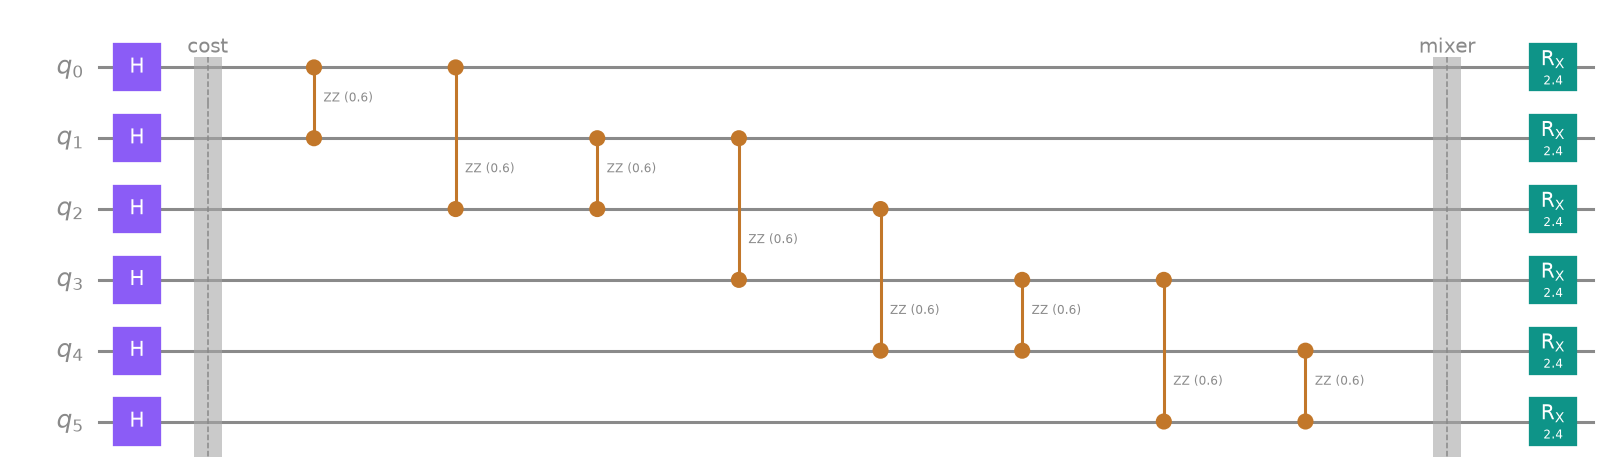

In [8]:
show(qaoa_circuit([0.6], [1.2]).draw("mpl", style=CIRCUIT, fold=-1))

Read the drawing from left to right. The Hadamards come first. The eight amber `rzz` boxes are the eight edges. The teal `rx` gates close the round. The angles in the drawing are placeholders until the next section.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#C2772A;">Section 4 · Tuning</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#C2772A;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#C2772A" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How do we choose <span style="color:#C2772A;">gamma and beta</span>?</div>

QAOA is a <b>variational</b> algorithm: the circuit has free angles, and a classical loop picks the angles that give the lowest energy. The quantity to minimize is the <b>expected energy</b> $\langle H \rangle$, the average of $H$ over many measurements.

With one round there are only two angles, so we can afford to look at every pair on a grid. Before you run it, predict: will the best region be a single point, or a stripe? The heatmap shows $\langle H \rangle$ for each pair. Darker means lower energy, which means larger cuts.

grid minimum <H> = -5.279 at gamma = 0.628, beta = 1.257


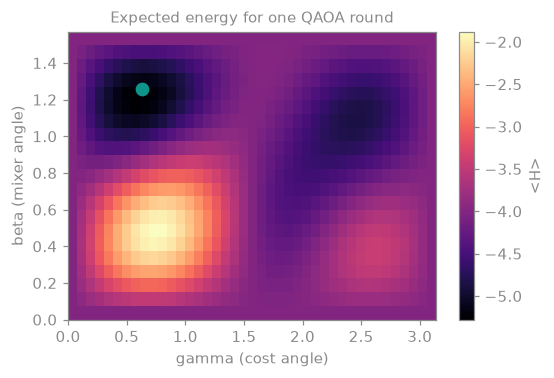

In [9]:
def expected_energy(angles):
    """<H> of the QAOA state; the first half of `angles` are gammas."""
    p = len(angles) // 2
    state = Statevector(qaoa_circuit(angles[:p], angles[p:]))
    return state.expectation_value(H).real


gammas = np.linspace(0, np.pi, 41)
betas = np.linspace(0, np.pi / 2, 21)
grid = np.array([[expected_energy([g, b]) for b in betas] for g in gammas])
i, j = np.unravel_index(grid.argmin(), grid.shape)
print(f"grid minimum <H> = {grid.min():.3f} at gamma = {gammas[i]:.3f}, beta = {betas[j]:.3f}")

fig, ax = plt.subplots(figsize=(5.4, 3.4))
image = ax.imshow(grid.T, origin="lower", aspect="auto", cmap="magma",
                  extent=[0, np.pi, 0, np.pi / 2])
ax.plot(gammas[i], betas[j], "o", color=TEAL, ms=8)
ax.set_xlabel("gamma (cost angle)")
ax.set_ylabel("beta (mixer angle)")
ax.set_title("Expected energy for one QAOA round", fontsize=10)
fig.colorbar(image, ax=ax, label="<H>")
show(fig)

The teal dot marks the lowest energy on the grid, about $-5.28$. The landscape has smooth valleys and hills, so a local optimizer can polish the grid point. We start COBYLA, a derivative-free optimizer from SciPy, at the dot.

In [10]:
from scipy.optimize import minimize

p1 = minimize(expected_energy, [gammas[i], betas[j]], method="COBYLA",
              options={"maxiter": 200})
print(f"p=1: <H> = {p1.fun:.3f}, expected cut = {-p1.fun:.3f}")

p=1: <H> = -5.291, expected cut = 5.291


A second round adds two more angles. A grid over four angles is too big to scan, so we let COBYLA do all the work. A good start helps: we repeat the one-round angles in both rounds. The plot tracks the energy at every step of the optimizer.

p=2: <H> = -5.711, expected cut = 5.711, 185 energy evaluations


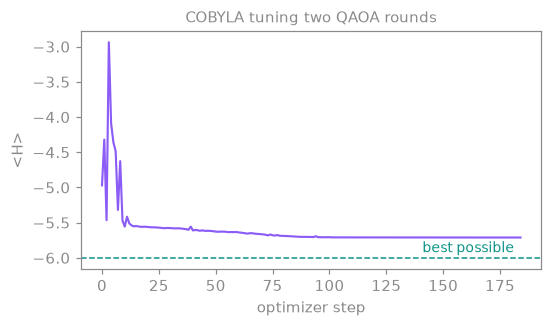

In [11]:
history = []


def tracked_energy(angles):
    energy = expected_energy(angles)
    history.append(energy)
    return energy


start = [p1.x[0], p1.x[0], p1.x[1], p1.x[1]]
p2 = minimize(tracked_energy, start, method="COBYLA", options={"maxiter": 300})
print(f"p=2: <H> = {p2.fun:.3f}, expected cut = {-p2.fun:.3f}, "
      f"{len(history)} energy evaluations")

fig, ax = plt.subplots(figsize=(5.4, 2.8))
ax.plot(history, color=VIOLET, lw=1.4)
ax.axhline(-best_cut, color=TEAL, ls="--", lw=1)
ax.text(len(history) * 0.98, -best_cut + 0.08, "best possible", color=TEAL,
        fontsize=9, ha="right")
ax.set_xlabel("optimizer step")
ax.set_ylabel("<H>")
ax.set_title("COBYLA tuning two QAOA rounds", fontsize=10)
show(fig)

The second round lowers the energy from about $-5.29$ to about $-5.71$. The dashed line at $-6$ is the best split. QAOA never reaches it on average, because the state still holds some weaker splits. What matters is how often a measurement returns a best one.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#C2772A;">Section 5 · Results</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#C2772A;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#C2772A" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How often does QAOA return a <span style="color:#C2772A;">best split</span>?</div>

Measuring the tuned circuit gives one split per shot. We take 1000 shots on the local simulator and score them two ways:

- the <b>approximation ratio</b>, the average cut found divided by the best cut, six;
- the <b>success probability</b>, the share of shots that land on one of the ten best splits.

The chart shows the eight most common splits. Teal bars are best splits; grey bars are not.

two rounds: approximation ratio 0.95, success 81%
random guessing: approximation ratio 0.67, success 16%


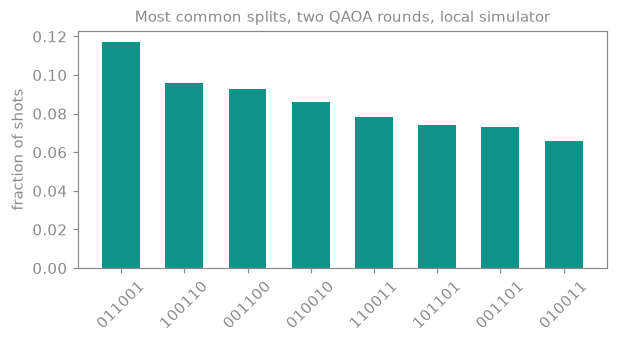

In [12]:
from qiskit_aer import AerSimulator


def local_counts(circuit, shots=1000):
    """Measure every qubit on the local simulator."""
    qc = circuit.measure_all(inplace=False)
    return AerSimulator(seed_simulator=SEED).run(qc, shots=shots).result().get_counts()


def score(counts):
    """Approximation ratio and success probability of a set of counts."""
    shots = sum(counts.values())
    mean_cut = sum(n * cut_size(bits_of(k)) for k, n in counts.items()) / shots
    success = sum(n for k, n in counts.items() if cut_size(bits_of(k)) == best_cut) / shots
    return mean_cut / best_cut, success


def plot_top(counts, title, top=8):
    shots = sum(counts.values())
    keys = sorted(counts, key=counts.get, reverse=True)[:top]
    colors = [TEAL if cut_size(bits_of(k)) == best_cut else GREY for k in keys]
    fig, ax = plt.subplots(figsize=(6.2, 2.8))
    ax.bar(keys, [counts[k] / shots for k in keys], color=colors, width=0.6)
    ax.set_ylabel("fraction of shots")
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", labelrotation=45)
    show(fig)


tuned = qaoa_circuit(p2.x[:2], p2.x[2:])
local = local_counts(tuned)
ratio, success = score(local)
print(f"two rounds: approximation ratio {ratio:.2f}, success {success:.0%}")
print(f"random guessing: approximation ratio {np.mean(cuts) / best_cut:.2f}, "
      f"success {len(best_splits) / len(splits):.0%}")
plot_top(local, "Most common splits, two QAOA rounds, local simulator")

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="display:flex;gap:26px;flex-wrap:wrap;"><div style="flex:1;min-width:120px;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:30px;color:#C2772A;line-height:1.1;">0.67</div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:10.5px;letter-spacing:1px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-top:6px;">random ratio</div></div><div style="flex:1;min-width:120px;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:30px;color:#C2772A;line-height:1.1;">16%</div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:10.5px;letter-spacing:1px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-top:6px;">random success</div></div><div style="flex:1;min-width:120px;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:30px;color:#C2772A;line-height:1.1;">0.95</div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:10.5px;letter-spacing:1px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-top:6px;">QAOA ratio, p = 2</div></div><div style="flex:1;min-width:120px;border-left:2px solid #C2772A;padding-left:14px;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:34px;color:#C2772A;line-height:1.1;">81%</div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:10.5px;letter-spacing:1px;text-transform:uppercase;color:#C2772A;margin-top:6px;">QAOA success, p = 2</div></div></div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;color:rgba(128,128,128,0.98);line-height:1.6;margin-top:16px;padding-top:12px;border-top:1px solid rgba(128,128,128,0.26);">Exact values from the tuned state. One round alone gives a ratio of 0.88 and 48% success. A sampled run differs by about one percentage point, which is shot noise.</div></div>

Four in five shots now return a best split, against one in six for random guessing. The next cell turns the most common split back into two teams and draws the cut twice. On the left the graph keeps its shape. On the right each team gets its own column, and the dashed line between them is the cut. A solid teal edge crosses the line, so it is cut. A dashed grey edge stays inside one team, so it is not cut.

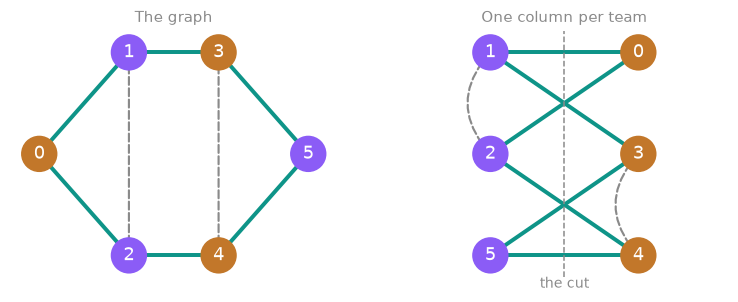

most common split 011001
cut edges (6): [(0, 1), (0, 2), (1, 3), (2, 4), (3, 5), (4, 5)]
uncut edges (2): [(1, 2), (3, 4)]


In [13]:
def draw_cut(teams):
    """Draw a split two ways: the graph's own layout, and one column per team."""
    colors = [VIOLET if b == 0 else AMBER for b in teams]
    cut = [(i, j) for i, j in EDGES if teams[i] != teams[j]]
    kept = [(i, j) for i, j in EDGES if teams[i] == teams[j]]
    columns = {}
    for side in (0, 1):
        members = [n for n in range(N) if teams[n] == side]
        for row, n in enumerate(members):
            columns[n] = (side, (len(members) - 1) / 2 - row)

    fig, axes = plt.subplots(1, 2, figsize=(8.4, 2.9))
    for ax, pos, title in [(axes[0], POS, "The graph"),
                           (axes[1], columns, "One column per team")]:
        bend = "arc3,rad=0.45" if pos is columns else "arc3"
        nx.draw_networkx_edges(graph, pos, edgelist=cut, ax=ax, edge_color=TEAL, width=2.6)
        nx.draw_networkx_edges(graph, pos, edgelist=kept, ax=ax, edge_color=GREY, width=1.4,
                               style="dashed", arrows=True, arrowstyle="-",
                               connectionstyle=bend)
        nx.draw_networkx_nodes(graph, pos, ax=ax, node_color=colors, node_size=520)
        nx.draw_networkx_labels(graph, pos, ax=ax, font_color="#FFFFFF")
        ax.set_title(title, fontsize=10, color=GREY)
        ax.axis("off")
    axes[1].axvline(0.5, color=GREY, ls="--", lw=1)
    axes[1].text(0.5, axes[1].get_ylim()[0], "the cut", color=GREY, ha="center",
                 va="top", fontsize=9)
    axes[1].set_xlim(-0.6, 1.6)
    show(fig)
    return cut, kept


top = max(local, key=local.get)
teams = bits_of(top)
cut, kept = draw_cut(teams)
print("most common split", top)
print(f"cut edges ({len(cut)}):", cut)
print(f"uncut edges ({len(kept)}):", kept)

Six edges cross the cut. Two do not: in the most common split, nodes 1 and 2 share the violet team, and nodes 3 and 4 share the amber team. That is not a mistake. Each triangle must keep one edge uncut, because two of its three nodes always land on the same team. So six of eight is the best any split can do, and this split reaches it.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#C2772A;">Section 6 · qBraid</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#C2772A;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#C2772A" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How do we run the circuit on a <span style="color:#C2772A;">qBraid device</span>?</div>

So far everything ran on your own machine. The qBraid SDK sends the same Qiskit circuit to cloud devices with one call. We use <code>aws:aws:sim:sv1</code>, the AWS state-vector simulator. SV1 computes the amplitudes exactly, the way `Statevector` did, then samples them. Its counts differ from the local run only by shot noise.

The helper below wraps the whole route:

- build a `QbraidProvider` and ask it for the SV1 device;
- transpile the circuit to basic gates, so the service accepts it;
- add one marker qubit fixed to 1, so the bit order of the answer is never in doubt;
- call `device.run`, wait for the result, and return the counts.

In qBraid Lab your account signs the request for you. On a laptop without qBraid credentials, the helper says so and runs locally instead.

In [14]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qbraid.exceptions import QbraidError
from qbraid.runtime import QbraidProvider

SV1 = "aws:aws:sim:sv1"


def strip_marker(raw):
    """Drop the marker bit and return keys in Qiskit order (last qubit first)."""
    left = all(key[0] == "1" for key in raw)
    right = all(key[-1] == "1" for key in raw)
    if left:
        return {key[1:]: n for key, n in raw.items()}
    if right:
        return {key[:-1][::-1]: n for key, n in raw.items()}
    raise ValueError("marker bit not found; were the counts measured with run_on_sv1?")


def run_on_sv1(circuit, shots=1000):
    """Run a measurement-free circuit on AWS SV1 through qBraid; return counts."""
    n = circuit.num_qubits
    qc = QuantumCircuit(n + 1)
    qc.compose(circuit, range(n), inplace=True)
    qc.x(n)  # marker qubit, always 1: it shows which end of each key is the last qubit
    qc.measure_all()
    qc = transpile(qc, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
    try:
        device = QbraidProvider().get_device(SV1)
    except QbraidError:
        print("No qBraid credentials here, so this ran on the local simulator. "
              "In qBraid Lab this cell submits to SV1.")
        raw = AerSimulator(seed_simulator=SEED).run(qc, shots=shots).result().get_counts()
    else:
        job = device.run(qc, shots=shots)
        print(f"submitted job {job.id} to {SV1}")
        print("follow it at https://account.qbraid.com/quantum-jobs")
        raw = job.result().data.get_counts()
    return strip_marker(raw)

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #C2772A;border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#C2772A;margin-bottom:7px;">What it costs</div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">One SV1 job of this size costs 0.375 qBraid credits. Recent jobs of 100 and 1000 shots cost the same. A parameter scan that sends every grid point as its own job costs 0.375 credits per point, so the 861 grid points of Section 4 would cost about 323 credits. Tune locally, then submit only the tuned circuit.</div></div>

Submit the tuned two-round circuit. Then compare its scores with the local run.

No qBraid credentials here, so this ran on the local simulator. In qBraid Lab this cell submits to SV1.
SV1: approximation ratio 0.95, success 81%


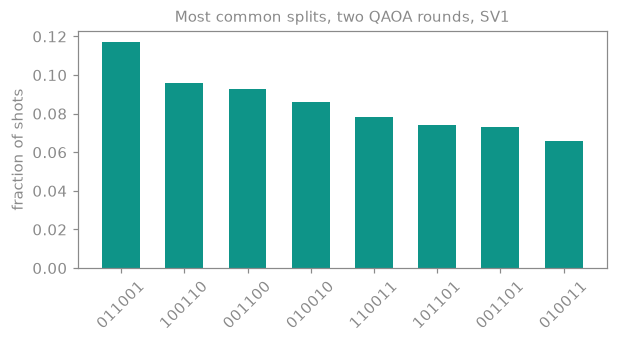

In [15]:
sv1 = run_on_sv1(tuned, shots=1000)
ratio, success = score(sv1)
print(f"SV1: approximation ratio {ratio:.2f}, success {success:.0%}")
plot_top(sv1, "Most common splits, two QAOA rounds, SV1")

The two runs agree to within a few percent. With 1000 shots the success rate wobbles by about $\sqrt{0.8 \times 0.2 / 1000} \approx 1.3$ percentage points from run to run. Your job also appears on the [quantum jobs page](https://account.qbraid.com/quantum-jobs), with its circuit, cost and result.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#C2772A;">Section 7 · Your challenge</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#C2772A;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#C2772A" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">What carries over to the <span style="color:#C2772A;">Instant Insanity</span> puzzle?</div>

The challenge asks you to stack four coloured cubes so each side of the tower shows every colour once. The QAOA recipe is the same:

- **Encode** each decision in qubits. In MaxCut a qubit is one node's group; for the cubes, groups of qubits pick which faces point where.
- **Score** every choice with a cost Hamiltonian whose lowest energy is the answer, and check it against brute force first.
- **Tune** the angles locally, then submit the tuned circuit with `run_on_sv1`.

One thing is new. Each cube must pick <i>exactly one</i> option from several. A plain encoding allows invalid states, so you add a <b>penalty</b>: extra energy for every rule broken. Penalties work, but they make the landscape rugged and the standard `rx` mixer wastes shots on invalid states.

A <b>constrained mixer</b> fixes that. It starts in a state where each cube already picks one option, and only moves amplitude between valid picks. The [starter notebook](../starter_notebook.ipynb) builds one and shows the difference it makes.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#C2772A;">Recap</span></div>

- **MaxCut** splits a graph's nodes into two groups to cut the most edges; brute force gave the exact target, a cut of 6.
- **A cost Hamiltonian** scores every split as an energy; here $H = \sum \tfrac{1}{2}(Z_i Z_j - 1)$, checked on all 64 splits.
- **QAOA** alternates a cost layer of `rzz` gates and a mixer layer of `rx` gates, with angles $\gamma$ and $\beta$ per round.
- **Tuning** is classical: a grid for one round, COBYLA for two.
- **The result** beats random guessing, 81% success against 16%.
- **qBraid** runs the same circuit on SV1 with `device.run`, for 0.375 credits a job.